# Экзаменационная задача №02. Критическая масса и ценность социальной сети

**Дисциплина:** Экономика информатизации, лекция №3
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №02: РАСЧЁТ КРИТИЧЕСКОЙ МАССЫ И ЦЕННОСТИ СОЦИАЛЬНОЙ СЕТИ
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №3)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Компания «ГородСоцСеть» запускает городскую соцсеть, рынок 1 млн жителей. Чем больше в сети людей, тем она полезнее
каждому (прямой сетевой эффект). Главный вопрос: **наберёт ли сеть критическую массу**, после которой она растёт сама,
и окупится ли проект за 3 года.

**Цель:** найти критическую массу и срок её достижения, ценность сети по закону Мэткалфа и NPV проекта,
предложить стратегию роста.

**Что нужно сделать:** (1) критическая масса; (2) когда она будет достигнута; (3) ценность сети $V=kN^2$ по месяцам;
(4) доходы и прибыль; (5) NPV за 36 месяцев и его зависимость от темпа роста; (6) минимальный ARPU для безубыточности;
(7) сколько вложить в маркетинг, чтобы дойти до критической массы на 6 месяцев раньше; (8) рекомендации.

Тема лекции №3: сетевые эффекты, закон Мэткалфа, критическая масса, проблема «курицы и яйца», «победитель получает всё».

## 2. Исходные данные

In [2]:
# 1.1. Параметры проекта (из условия)
M = 1_000_000        # потенциал рынка, чел.
N0 = 5_000           # начальное число пользователей
g_before = 0.03      # прирост в месяц до критической массы
g_after = 0.15       # прирост в месяц после критической массы
k = 0.005            # коэффициент ценности сети, руб./пользователь²
F = 2_000_000        # затраты на поддержание сети, руб./мес.
CAC = 500            # стоимость привлечения пользователя, руб.
ARPU = 15            # доход с пользователя, руб./мес.
T = 36               # горизонт, мес.
r_m = 0.01           # ставка дисконтирования, в месяц (12% годовых / 12)
pd.DataFrame({"Параметр": ["M", "N0", "g до КМ", "g после КМ", "k", "Затраты/мес.", "CAC", "ARPU", "Горизонт, мес.", "r в месяц"],
              "Значение": pd.Series([M, N0, g_before, g_after, k, F, CAC, ARPU, T, r_m], dtype=object)})

,Параметр,Значение
0,M,1000000
1,N0,5000
2,g до КМ,0.03
3,g после КМ,0.15
4,k,0.01
5,Затраты/мес.,2000000
6,CAC,500
7,ARPU,15
8,"Горизонт, мес.",36
9,r в месяц,0.01


**Допущения:**
- Пользователей становится больше по экспоненте: $N_{t+1} = N_t(1+g)$, но не больше размера рынка $M$.
- Каждый новый пользователь стоит CAC (платный маркетинг). Отток не учитываем, в условии его нет.
- Деньги приходят в конце каждого месяца с 1 по 36. Ставка 1 % в месяц (упрощение, точное значение 0,949 %).

## 3. Математическая модель

**Критическая масса** это минимальное число пользователей $N$, при котором доход покрывает расходы на поддержку сети
и на привлечение прироста $\Delta N = gN$:
$$ARPU\cdot N \ge F + CAC\cdot g\cdot N \;\Rightarrow\; N_{крит} = \frac{F}{ARPU - CAC\cdot g}, \quad ARPU > CAC\cdot g.$$
Если $ARPU \le CAC\cdot g$, новый пользователь обходится дороже, чем приносит за месяц, и при таком темпе роста
сеть сама себя не окупит. «Операционная» критическая масса, без расходов на привлечение: $N_{оп}=F/ARPU$.

**Время достижения:** $t^* = \dfrac{\ln(N_{крит}/N_0)}{\ln(1+g)}$.

**Ценность сети (Мэткалф):** $V(N)=kN^2$. **Доход:** $R(N)=ARPU\cdot N$. **Прибыль за месяц:** $\Pi_t = R(N_t) - F - CAC\cdot\Delta N_t$.

**NPV:** $NPV=\sum_{t=1}^{36}\Pi_t/(1+r_m)^t$.

## 4. Реализация расчёта
### 4.1. Критическая масса и время её достижения

In [3]:
# 2.1. Критическая масса
margin_per_user = ARPU - CAC * g_before          # месячная "маржа" пользователя с учётом привлечения прироста
N_oper = F / ARPU                                # операционная критическая масса (без CAC)
print(f"ARPU − CAC·g = {ARPU} − {CAC}·{g_before} = {margin_per_user:.2f} руб.")
if margin_per_user <= 0:
    print("→ При CAC = 500 руб. и росте 3% затраты на привлечение прироста равны доходу пользователя:\n"
          "  критическая масса с учётом CAC НЕ ДОСТИЖИМА ни при каком N (знаменатель ≤ 0).")
print(f"Операционная критическая масса N_оп = F/ARPU = {N_oper:,.0f} чел. ({N_oper/M:.1%} рынка)".replace(",", " "))

# Какой CAC делает критическую массу достижимой и какой она тогда будет
cac_grid = pd.DataFrame({"CAC, руб.": [50, 100, 200, 300, 400, 450]})
cac_grid["N_крит (g=3%)"] = F / (ARPU - cac_grid["CAC, руб."] * g_before)
cac_grid["Доля рынка"] = cac_grid["N_крит (g=3%)"] / M
cac_grid

ARPU − CAC·g = 15 − 500·0.03 = 0.00 руб.
→ При CAC = 500 руб. и росте 3% затраты на привлечение прироста равны доходу пользователя:
  критическая масса с учётом CAC НЕ ДОСТИЖИМА ни при каком N (знаменатель ≤ 0).
Операционная критическая масса N_оп = F/ARPU = 133 333 чел. (13.3% рынка)


,"CAC, руб.",N_крит (g=3%),Доля рынка
0,50,148 148.15,0.15
1,100,166 666.67,0.17
2,200,222 222.22,0.22
3,300,333 333.33,0.33
4,400,666 666.67,0.67
5,450,1 333 333.33,1.33


In [4]:
# 2.2. Время достижения операционной критической массы при 3% в месяц
t_star = math.log(N_oper / N0) / math.log(1 + g_before)
print(f"t* = ln({N_oper:,.0f}/{N0}) / ln(1.03) = {t_star:.1f} мес. ≈ {t_star/12:.1f} лет".replace(",", " "))
print(f"За 36 месяцев база вырастет только до {N0*(1+g_before)**T:,.0f} чел.".replace(",", " "))
# Темп роста, нужный для достижения КМ в пределах горизонта
g_need = (N_oper / N0) ** (1 / T) - 1
print(f"Чтобы достичь КМ за 36 мес., нужен рост {g_need:.2%} в месяц")

t* = ln(133 333/5000) / ln(1.03) = 111.1 мес. ≈ 9.3 лет
За 36 месяцев база вырастет только до 14 491 чел.
Чтобы достичь КМ за 36 мес., нужен рост 9.55% в месяц


### 4.2. Помесячная модель: пользователи, ценность сети, доход, прибыль

In [5]:
def simulate(g1=g_before, g2=g_after, arpu=ARPU, cac=CAC, n0=N0, n_crit=None, months=T):
    """Помесячная модель сети. Переключение на быстрый рост — после достижения n_crit."""
    n_crit = F / arpu if n_crit is None else n_crit
    N = [n0]; reached = None
    for t in range(1, months + 1):
        g = g2 if N[-1] >= n_crit else g1
        if reached is None and N[-1] >= n_crit:
            reached = t - 1
        N.append(min(M, N[-1] * (1 + g)))
    df = pd.DataFrame({"Месяц": range(months + 1), "Пользователи N": N})
    df["Новые ΔN"] = df["Пользователи N"].diff().fillna(0)
    df["Ценность V=kN², руб."] = k * df["Пользователи N"] ** 2
    df["Доход R, руб."] = arpu * df["Пользователи N"]
    df["Затраты F, руб."] = F
    df["CAC·ΔN, руб."] = cac * df["Новые ΔN"]
    df["Прибыль П, руб."] = df["Доход R, руб."] - F - df["CAC·ΔN, руб."]
    df.loc[0, ["Прибыль П, руб."]] = 0          # месяц 0 — точка старта, потоки с 1-го месяца
    df["Дисконт. П"] = df["Прибыль П, руб."] / (1 + r_m) ** df["Месяц"]
    return df, reached

base, reached = simulate()
print("Критическая масса в горизонте 36 мес.:", "не достигнута" if reached is None else f"месяц {reached}")
base.iloc[[0, 1, 6, 12, 18, 24, 30, 36]].set_index("Месяц").round(0)

Критическая масса в горизонте 36 мес.: не достигнута


,Пользователи N,Новые ΔN,"Ценность V=kN², руб.","Доход R, руб.","Затраты F, руб.","CAC·ΔN, руб.","Прибыль П, руб.",Дисконт. П
Месяц,,,,,,,,
0,5 000.00,0.00,125 000.00,75 000.00,2000000,0.00,0.00,0.00
1,5 150.00,150.00,132 612.00,77 250.00,2000000,75 000.00,-1 997 750.00,-1 977 970.00
6,5 970.00,174.00,178 220.00,89 554.00,2000000,86 946.00,-1 997 392.00,-1 881 633.00
12,7 129.00,208.00,254 099.00,106 932.00,2000000,103 818.00,-1 996 885.00,-1 772 134.00
18,8 512.00,248.00,362 285.00,127 682.00,2000000,123 964.00,-1 996 281.00,-1 668 926.00
24,10 164.00,296.00,516 531.00,152 460.00,2000000,148 019.00,-1 995 559.00,-1 571 635.00
30,12 136.00,353.00,736 450.00,182 045.00,2000000,176 742.00,-1 994 698.00,-1 479 912.00
36,14 491.00,422.00,1 050 002.00,217 371.00,2000000,211 040.00,-1 993 669.00,-1 393 425.00


### 4.3. NPV и сценарии роста

In [6]:
def project_npv(**kw):
    df, _ = simulate(**kw)
    return df["Дисконт. П"].sum()

scenarios = {"Пессимистичный (2% / 10%)": (0.02, 0.10), "Базовый (3% / 15%)": (0.03, 0.15), "Оптимистичный (5% / 20%)": (0.05, 0.20)}
res = []
for name, (g1, g2) in scenarios.items():
    df, rch = simulate(g1, g2)
    res.append({"Сценарий": name, "N через 36 мес.": df["Пользователи N"].iloc[-1],
                "КМ достигнута": "нет" if rch is None else f"мес. {rch}",
                "Суммарная прибыль, млн": df["Прибыль П, руб."].sum() / 1e6,
                "NPV, млн руб.": df["Дисконт. П"].sum() / 1e6})
npv_table = pd.DataFrame(res).set_index("Сценарий")
npv_table

,N через 36 мес.,КМ достигнута,"Суммарная прибыль, млн","NPV, млн руб."
Сценарий,,,,
Пессимистичный (2% / 10%),10 199.44,нет,-70.62,-59.09
Базовый (3% / 15%),14 491.39,нет,-71.86,-60.10
Оптимистичный (5% / 20%),28 959.08,нет,-76.43,-63.74


In [7]:
# Длинный горизонт: что будет, если сеть всё-таки дойдёт до КМ (для понимания механики)
long_df, long_reached = simulate(months=150)
print(f"При 3%/15% КМ достигается на {long_reached}-м месяце, рынок насыщается к месяцу "
      f"{int(long_df[long_df['Пользователи N'] >= M].iloc[0]['Месяц'])}")
print(f"NPV за 150 мес.: {long_df['Дисконт. П'].sum()/1e6:,.1f} млн руб.")

При 3%/15% КМ достигается на 112-м месяце, рынок насыщается к месяцу 127
NPV за 150 мес.: -163.1 млн руб.


### 4.4. Минимальный ARPU для безубыточности

In [8]:
from utils.calculations import solve_for
arpu_be = solve_for(lambda a: project_npv(arpu=a), 0, 1, 2000)
df_be, reached_be = simulate(arpu=arpu_be)
print(f"Минимальный ARPU, при котором NPV(36 мес.) = 0: {arpu_be:.1f} руб./мес. (в {arpu_be/ARPU:.1f} раза выше текущего)")
print(f"При таком ARPU операционная КМ = {F/arpu_be:,.0f} чел.; достигнута: {'нет' if reached_be is None else f'мес. {reached_be}'}".replace(",", " "))
# Без учёта ARPU-зависимости КМ: простая проверка "N в конце горизонта × ARPU = F"
print(f"Для сравнения: чтобы покрыть F при N36 = {base['Пользователи N'].iloc[-1]:,.0f}, ARPU должен быть ≥ {F/base['Пользователи N'].iloc[-1]:.0f} руб.".replace(",", " "))

Минимальный ARPU, при котором NPV(36 мес.) = 0: 196.8 руб./мес. (в 13.1 раза выше текущего)
При таком ARPU операционная КМ = 10 164 чел.; достигнута: мес. 24
Для сравнения: чтобы покрыть F при N36 = 14 491  ARPU должен быть ≥ 138 руб.


### 4.5. Сколько стоит ускориться на 6 месяцев

Без вложений операционная критическая масса наступит примерно через 111 месяцев. Сравним два способа сократить срок на 6 месяцев:
1. **Разово купить стартовую базу**: увеличить $N_0$ так, чтобы $N_0'(1{,}03)^{t^*-6}=N_{оп}$.
2. **Постоянно ускорять рост**: поднять месячный темп $g$ так, чтобы $t'=t^*-6$. Пользователей сверх базового прогноза
   оплачиваем по CAC.

In [9]:
# Способ 1: увеличить стартовую базу
t_target = t_star - 6
N0_new = N_oper / (1 + g_before) ** t_target
extra_users = N0_new - N0
invest1 = extra_users * CAC
print(f"Способ 1: N0' = {N0_new:,.0f} → доп. {extra_users:,.0f} пользователей × {CAC} руб. = {invest1/1e6:.2f} млн руб.".replace(",", " "))

# Способ 2: ускорить рост
g_new = (N_oper / N0) ** (1 / t_target) - 1
traj_base = N0 * (1 + g_before) ** np.arange(0, int(np.ceil(t_target)) + 1)
traj_new = np.minimum(N_oper, N0 * (1 + g_new) ** np.arange(0, int(np.ceil(t_target)) + 1))
extra2 = (traj_new - traj_base).clip(min=0)
invest2 = (np.diff(traj_new) - np.diff(traj_base)).clip(min=0).sum() * CAC
print(f"Способ 2: рост {g_new:.3%} вместо 3% → доп. привлечение ≈ {invest2/1e6:.1f} млн руб.")

# Способ 3: достичь КМ в пределах горизонта 36 мес. (на 75 мес. раньше) — для сравнения
invest3 = ((N_oper - N0) - (N0 * (1 + g_before) ** T - N0)) * CAC
print(f"Справочно: достичь КМ за 36 мес. (рост {g_need:.1%}/мес.) — доп. маркетинг ≈ {invest3/1e6:.1f} млн руб.")

Способ 1: N0' = 5 970 → доп. 970 пользователей × 500 руб. = 0.49 млн руб.
Способ 2: рост 3.174% вместо 3% → доп. привлечение ≈ 10.8 млн руб.
Справочно: достичь КМ за 36 мес. (рост 9.5%/мес.) — доп. маркетинг ≈ 59.4 млн руб.


## 5. Визуализация результатов

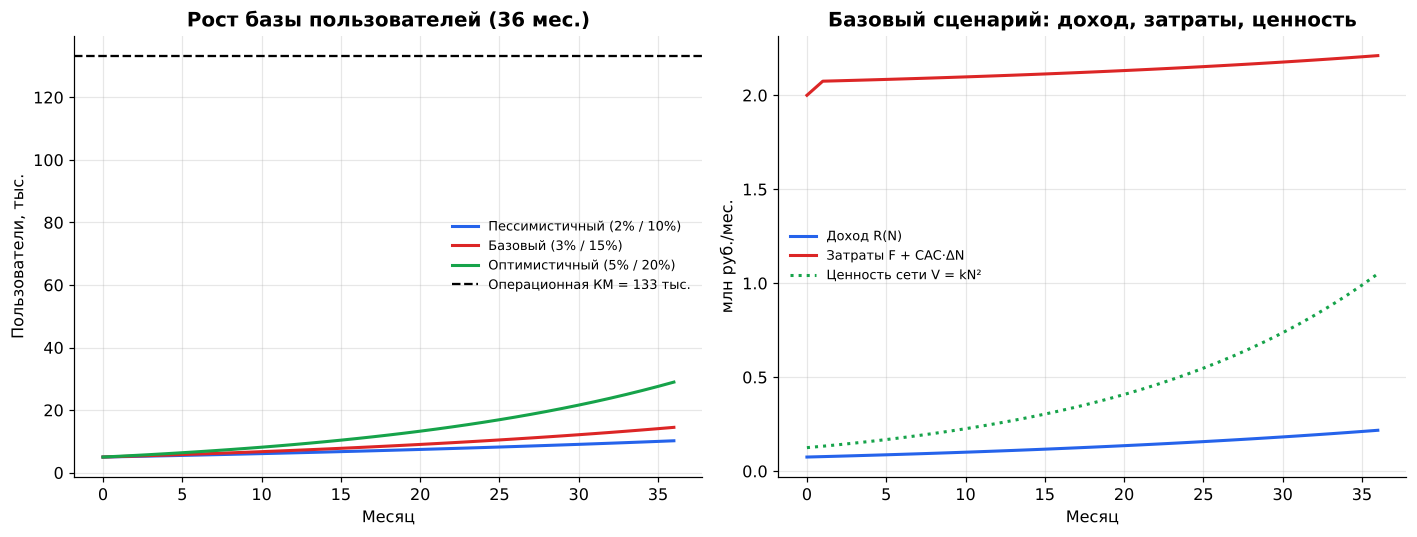

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for name, (g1, g2) in scenarios.items():
    df, _ = simulate(g1, g2)
    ax.plot(df["Месяц"], df["Пользователи N"] / 1e3, lw=2, label=name)
ax.axhline(N_oper / 1e3, ls="--", color="black", label=f"Операционная КМ = {N_oper/1e3:.0f} тыс.")
ax.set_xlabel("Месяц"); ax.set_ylabel("Пользователи, тыс."); ax.set_title("Рост базы пользователей (36 мес.)")
ax.legend(fontsize=8.5)
ax = axes[1]
ax.plot(base["Месяц"], base["Доход R, руб."] / 1e6, lw=2, label="Доход R(N)")
ax.plot(base["Месяц"], (F + base["CAC·ΔN, руб."]) / 1e6, lw=2, label="Затраты F + CAC·ΔN")
ax.plot(base["Месяц"], base["Ценность V=kN², руб."] / 1e6, lw=2, ls=":", label="Ценность сети V = kN²")
ax.set_xlabel("Месяц"); ax.set_ylabel("млн руб./мес."); ax.set_title("Базовый сценарий: доход, затраты, ценность")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

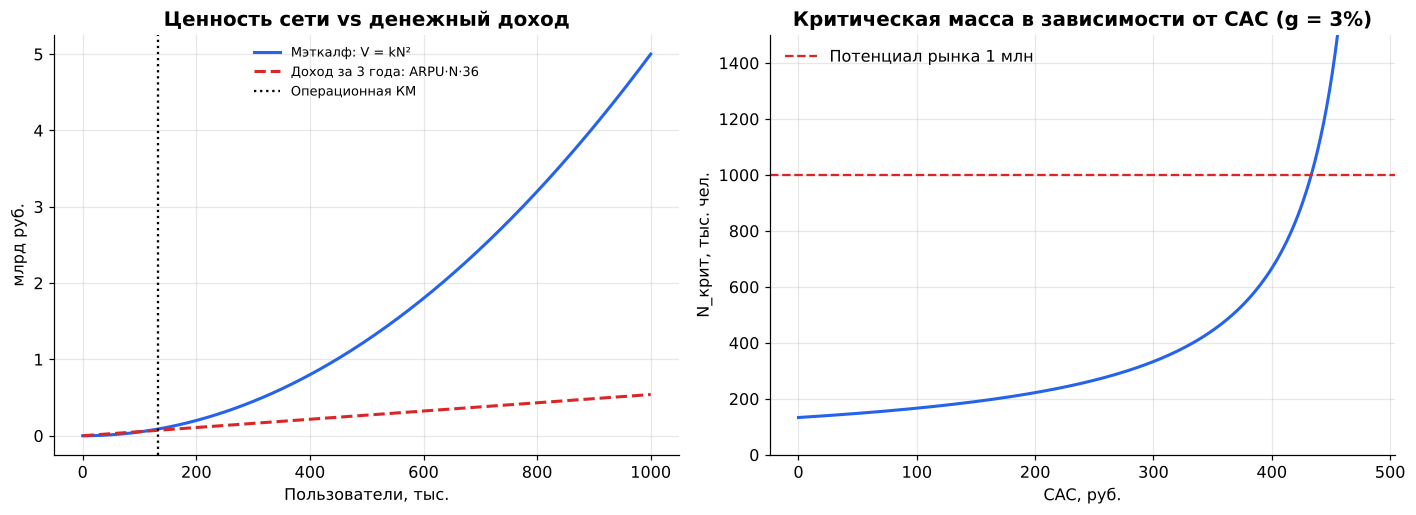

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
Ns = np.linspace(0, M, 300)
ax.plot(Ns / 1e3, k * Ns**2 / 1e9, lw=2, label="Мэткалф: V = kN²")
ax.plot(Ns / 1e3, ARPU * Ns * 12 * 3 / 1e9, lw=2, ls="--", label="Доход за 3 года: ARPU·N·36")
ax.axvline(N_oper / 1e3, color="black", ls=":", label="Операционная КМ")
ax.set_xlabel("Пользователи, тыс."); ax.set_ylabel("млрд руб."); ax.set_title("Ценность сети vs денежный доход")
ax.legend(fontsize=8.5)
ax = axes[1]
cac_line = np.linspace(0, 480, 200)
ax.plot(cac_line, F / (ARPU - cac_line * g_before) / 1e3, lw=2)
ax.axhline(M / 1e3, color=PALETTE[1], ls="--", label="Потенциал рынка 1 млн")
ax.set_ylim(0, 1500); ax.set_xlabel("CAC, руб."); ax.set_ylabel("N_крит, тыс. чел.")
ax.set_title("Критическая масса в зависимости от CAC (g = 3%)"); ax.legend()
plt.tight_layout(); plt.show()

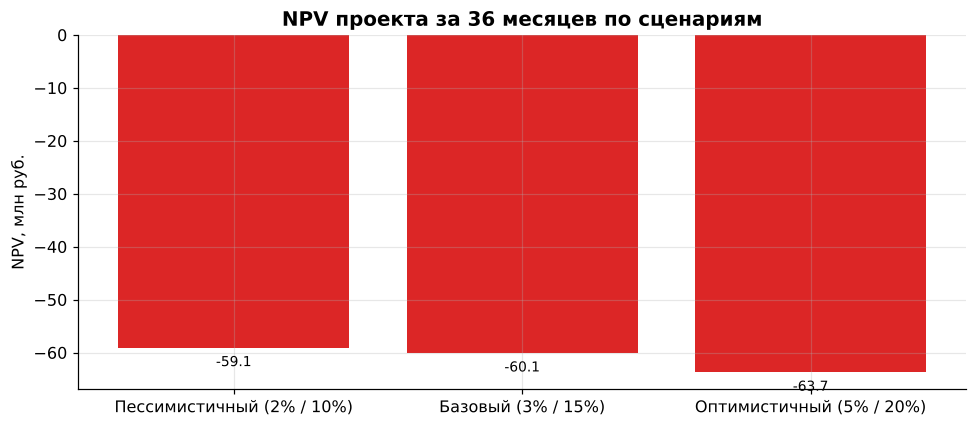

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(npv_table.index, npv_table["NPV, млн руб."], color=[PALETTE[1]] * 3)
bar_labels(ax, bars, "{:.1f}")
ax.set_ylabel("NPV, млн руб."); ax.set_title("NPV проекта за 36 месяцев по сценариям")
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

1. **С учётом CAC критическая масса недостижима.** При CAC 500 руб. и росте 3 % привлечение стоит
   $500\cdot0{,}03 = 15$ руб. в месяц на каждого пользователя. Ровно столько пользователь и приносит (ARPU 15 руб.).
   Сеть, которая растёт только за счёт платной рекламы, никогда не начнёт окупаться сама. При росте 15 % ещё хуже:
   $500\cdot0{,}15=75 > 15$. Быстрый рост возможен, только если люди приходят сами (**виральность**, CAC близок к нулю).
2. **Операционная критическая масса около 133 тыс. пользователей** (13 % рынка). При ней доход покрывает расходы на поддержку.
   При росте 3 % до неё около 111 месяцев (9 лет), то есть далеко за пределами 3 лет.
3. **NPV за 3 года отрицательный во всех сценариях** (от −59 до −64 млн руб.). Даже при росте 5 % в месяц сеть не выходит
   на критическую массу за 36 месяцев, для этого нужно около 9,5 %. Интересно, что оптимистичный сценарий даёт *худший* NPV:
   пользователь стоит 500 руб., а приносит 15 руб. в месяц и окупается за 33 месяца, почти за весь срок проекта.
   Чем больше покупаем пользователей, тем больше убыток. Даже на 150 месяцах, с выходом на критическую массу и насыщением рынка,
   NPV остаётся отрицательным (около −163 млн руб.) из-за расходов на привлечение.
4. **Ценность по Мэткалфу** растёт как квадрат: при 133 тыс. пользователей около 89 млн руб., при всём рынке 5 млрд руб.
   Но это ценность сети для людей, а не деньги компании: доход через ARPU 15 руб. растёт линейно.
   Разница между $kN^2$ и $ARPU\cdot N$ говорит о том, что нужны другие источники дохода (местная реклама, сервисы).
5. **Безубыточный ARPU** на 36 месяцах в разы выше текущего: при нынешнем росте сеть слишком маленькая.
6. **Ускориться на 6 месяцев** дёшево (около 0,5 млн руб. на разовую покупку базы), но это мало что даёт:
   критическая масса всё равно наступит через 8,7 лет. Чтобы успеть за 3 года, нужно около 60 млн руб. на маркетинг при CAC 500 руб.

## 7. Выводы и рекомендации

### 7.1. Выводы
- При таких параметрах проект **невыгоден**: NPV около −60 млн руб., критическая масса за 3 года не набирается.
- Причина в соотношении CAC и ARPU: при $CAC\cdot g \ge ARPU$ платный рост съедает весь доход.
- Проект становится реальным, если снизить CAC в 5–10 раз (виральность) и/или поднять ARPU.

### 7.2. Как набрать критическую массу
| Направление | Что делать | Зачем |
|---|---|---|
| Виральный рост | реферальная программа, приглашения соседей, интеграция с мессенджерами | CAC снижается до 50–100 руб. |
| Запуск по районам | начать с 1–2 районов, чтобы сеть была плотной | критическая масса набирается в маленьком сегменте, это решает проблему «курицы и яйца» |
| Две стороны платформы | привлечь местный бизнес: кафе, УК, школы | ARPU растёт за счёт рекламы и услуг для бизнеса |
| Меньше постоянных расходов | облако, команда растёт постепенно | ниже операционная критическая масса |
| Полезный контент с первого дня | городские новости, ЖКХ, объявления | сеть полезна даже первому пользователю |

**Когда запускать:** если пилот в одном районе покажет CAC не выше 100 руб. и ARPU не ниже 30 руб.
Если нет, менять модель заработка или отказаться от проекта.